# 7.2.3 - Model: Random Forest Lite (Lancaster-stemmed variant)

**Finding and training the "lite" variant of the Random Forest classifier - with a significantly smaller .joblib file and minimal loss of F1 score compared to the heavy version from `7.1.3`.**

## Motivation

In `7.1.3`, GridSearchCV selected `max_depth=500, min_samples_leaf=2, n_estimators=1500` for the baseline variant, resulting in a model of **199MB** (F1 = 0.8786).

For the purposes of this work, a file of that size is impractical for storage and sharing, while almost all other models in this work are below 2MB.

The goal of this file is not to find the best possible F1 (that has already been done in `7.1.3`), but to find a reasonable compromise between file size and F1 score, i.e. a "lite" version that:
- targets a file size that does not differ too much from the other `.joblib` files, i.e. not (much) larger than 10MB
- keeps the F1 as close as possible to the heavy version
- is saved separately from the original model, for comparison in `10_evaluation.ipynb`

## Why GridSearchCV from `train_and_evaluate()` is not sufficient here

`train_and_evaluate()` (from `src/modeling.py`) selects hyperparameters exclusively based on F1 score - it has no knowledge of the size of the resulting file.

To find a combination that balances F1 and size, we first have to manually explore the hyperparameter space and measure both for each combination.

Only after selecting the final combination do we call `train_and_evaluate()` with that one (fixed) combination in order to obtain the official, saved model, metrics, and confusion matrix - in the same way as with all other models in this work.

## Hyperparameters

- `n_estimators` - number of trees in the forest
  - More trees → more stable, reliable results (averaging over more "votes")
  - But also slower training - each additional tree increases training time

- `max_depth` - maximum depth of each individual tree in the forest

- `max_features` - how many features are randomly considered at each split
  - `"sqrt"` - considers √68.378 ≈ 261 features per split
  - `"log2"` - considers log₂(68.378) ≈ 18 features per split
  - Fewer features per split means more diverse trees (a lower chance that two trees make the same split), which can improve the ensemble effect

- `min_samples_leaf` - minimum number of samples that a leaf must contain for a split to be allowed
  - A higher value prevents the creation of very small leaves and therefore further regularizes the model

## Which hyperparameters we examine and which we fix

From `7.1.x` we know that `max_features='log2'` performed best (and it intuitively makes sense - fewer features per split means more diverse trees), so we fix it.

We focus on three hyperparameters that directly determine file size:

- `max_depth`:
    - The biggest "driver" of size
    - With 39.665 training examples, a fully balanced tree would theoretically need a depth of only ~15 to separate all examples
    - We expect F1 to increase quickly up to some moderate depth and then slow down, while file size grows almost linearly (deeper trees = more nodes)

- `min_samples_leaf`:
    - In `7.1.3`, 2 was selected, which allows relatively small leaves and contributes to the larger size
    - We expect larger values to minimally reduce F1 while significantly reducing size

- `n_estimators`:
    - We expect size to grow approximately linearly with the number of trees, while the F1 gain from additional trees quickly diminishes after several hundred/thousand.

<br>

<br>

## Theoretical Background

Random Forest is an ensemble method - instead of training a single tree (as in `6.3`), it trains many independent Decision Tree models and combines their predictions into one final decision in order to obtain a more stable and accurate classifier.

Each tree in the forest is built in a slightly different way than a standard Decision Tree:
- Bootstrap sampling (bagging) - each tree is trained on its own random sample of the TRAIN set, drawn with replacement (the same sample can appear multiple times, while some samples can be completely omitted)
- Random subset of features per split - at each node split, the tree does not consider all features (as a standard Decision Tree does), but only a randomly selected subset (controlled by the `max_features` parameter)
- More trees – the number of trees in the forest is determined by the `n_estimators` parameter (a larger number of trees generally gives more stable results, but increases training time).

The final prediction of the entire forest is a majority vote of all individual trees.

Why this helps:
- An individual tree is unstable - a small change in the training data can produce a completely different tree, and it is prone to overfitting
- By averaging over many different, weakly dependent trees, the errors of individual trees cancel each other out, and the forest as a whole generalizes better to new data

Cost:
- We lose the direct interpretability of an individual tree (now we have many trees instead of one, so we cannot simply "follow" a single sequence of decisions)
- We retain some degree of interpretability through `feature_importances_` (averaged across all trees in the forest, instead of from a single tree as in `6.3`)

## Note on the name `max_features`

`max_features` here is not the same parameter as `max_features` from `3_vectorization.ipynb` (there it controlled the size of the entire TF-IDF vocabulary).

`max_features` here controls how many features are randomly considered at each individual node split within a single tree.

## Processing Flow:

1. We load the previously prepared Lancaster-stemmed TF-IDF data using the `load_variant()` function

2. Coarse search - we examine a wide range of hyperparameters to get a rough picture of the relationship between F1 and file size

3. Fine search - we examine in more detail the range of hyperparameters that produced the best results in the coarse search

4. Display and selection of the final combination of hyperparameters for which we obtained the best F1-to-file-size ratio

5. We call the shared `train_and_evaluate()` function for the predetermined hyperparameters

6. We analyze `feature_importances_` (averaged across all trees in the forest) to see which terms contribute most to the decisions


In [1]:
import sys
sys.path.append("..")

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

TMP_MODEL_PATH = Path("../models/_tmp_lite_search.joblib")

## Data Loading

We load the Lancaster-stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lancaster")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 68378)
Test:  (9917, 68378)


## Helper function for measuring F1 and file size

For each combination of hyperparameters:

1. We estimate F1 using 5-fold cross-validation on the TRAIN set (`cross_val_score`) (the same number of folds as in `train_and_evaluate()`, for comparability and credibility of the F1 values without touching the TEST set)

2. We train the model on the entire TRAIN set (the same thing that happens in the final step) and temporarily save it to disk in order to measure the actual size of the `.joblib` file (the size depends on the structure of the trained trees and cannot be reliably estimated without actually saving the file)

3. We delete the temporary file after measurement (we do not clutter the `models/` folder with intermediate results)

The TEST set is not used at all during this research phase - it is reserved for the final evaluation of the selected model, following the same principle used by `train_and_evaluate()`.

`evaluate_combo` - for a given combination of hyperparameters, returns the estimated CV F1 and the size (in MB) of the resulting `.joblib` file trained on the entire TRAIN set.


In [3]:
def evaluate_combo(max_depth, min_samples_leaf, n_estimators, max_features="log2"):
    model = RandomForestClassifier(
        max_depth=max_depth,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1,
    )

    start = time.time()

    # F1 procena (bez čuvanja modela) kao srednja vrednost od 5-fold cross-validation
    cv_f1 = cross_val_score(model, X_train, y_train, cv=5, scoring="f1", n_jobs=-1).mean()

    # Trening na celom TRAIN skupu, radi merenja stvarne veličine fajla
    model.fit(X_train, y_train)
    joblib.dump(model, TMP_MODEL_PATH)
    size_mb = TMP_MODEL_PATH.stat().st_size / (1024 ** 2)
    TMP_MODEL_PATH.unlink()                                 # brišemo privremeni fajl

    elapsed = time.time() - start

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "n_estimators": n_estimators,
        "f1": cv_f1,
        "size_mb": size_mb,
        "time_s": elapsed,
    }

## Step 1: Coarse Search

We examine a wide range of `max_depth` values (including the one from `7.1.3`, `max_depth=500`, for comparison), combined with `min_samples_leaf` and `n_estimators`, in order to get a rough picture of the relationship between F1 and file size before focusing on a narrower region.


In [4]:
coarse_max_depth = [10, 50, 200, 500]
coarse_min_samples_leaf = [2, 3]
coarse_n_estimators = [1000, 1500, 2000]

coarse_results = []
for depth in coarse_max_depth:
    for leaf in coarse_min_samples_leaf:
        for n_est in coarse_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            coarse_results.append(result)

coarse_df = pd.DataFrame(coarse_results)

coarse_df.style.format({"f1": "{:.4f}", "size_mb": "{:.1f}", "time_s": "{:.0f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb,time_s
0,10,2,1000,0.8437,3.4,38
1,10,2,1500,0.8491,5.1,49
2,10,2,2000,0.8497,6.8,55
3,10,3,1000,0.8434,2.9,27
4,10,3,1500,0.8491,5.7,32
5,10,3,2000,0.8491,5.8,27
6,50,2,1000,0.8699,25.7,24
7,50,2,1500,0.8711,38.7,35
8,50,2,2000,0.8713,51.5,46
9,50,3,1000,0.8696,17.2,22


## Commentary on the Coarse Search

The results confirm the expected trade-off between F1 score and model size and support the assumptions from the introduction:

- `max_depth`
    - **The dominant factor determining model size, with clearly diminishing returns on F1**
    - The results confirm the main hypotheses from the introduction and clearly demonstrate the trade-off between F1 score and model size
    - Average F1 increases from: 0.8474 (10) -> 0.8707 (50) -> 0.8765 (200) -> 0.8779 (500)
    - Average size increases from: 4.72 MB (10) -> 32.27 MB (50) -> 116.88 MB (200) -> 154.15 MB (500)
    - From 10 to 50, F1 increases by ~0.023 for a ~6.8x larger file -> a relatively good trade-off if model size is not strictly constrained
    - From 50 to 500, F1 increases by only ~0.007 for a file that is ~4.8x larger -> a significantly smaller gain in F1 relative to the additional model size

- `min_samples_leaf`
    - **2 vs. 3 has a negligible impact on F1, but a noticeable impact on size**
    - For `min_samples_leaf=2`, the average F1 is around 0.8684, while the average size is around 97.38 MB
    - For `min_samples_leaf=3`, the average F1 is around 0.8678, while the average size drops to around 56.63 MB
    - By switching from `leaf=2` to `leaf=3`, we lose only around 0.0007 F1, while reducing model size by around 42%
    - The effect is particularly pronounced at large depths (for `max_depth=500` and `n_estimators=1000`, a loss of 0.0015 F1 results in a reduction in model size of around 45%)
    - This represents a useful way to regularize and reduce model size
    - The fine search should also test values greater than 3

- `n_estimators`
    - **Model size and training time grow approximately linearly, while the gain in F1 quickly diminishes**
    - In most of the combinations tested, moving from 1000 to 1500 trees brings only a small improvement in F1
    - Moving from 1500 to 2000 generally brings an even smaller gain or even a slight decrease in F1
    - Therefore, after approximately 1000-1500 trees, additional trees generally provide very little gain, while still significantly increasing file size and training time

Based on the coarse search:
- `max_depth` proves to be the most important parameter for finding a lite model, because it directly controls how complex individual trees can be and therefore how many nodes, and consequently how much data, the model must store.
- `min_samples_leaf` proves to be a useful additional mechanism for reducing size with a relatively small loss in F1
- `n_estimators` should be kept at moderately high values because after a certain number of trees, the gain in F1 quickly diminishes.

None of the combinations from the coarse search come close to our target size (~10MB) while maintaining a satisfactory F1.

There is a large gap between `max_depth=10` (average ~4.72MB) and `max_depth=50` (average ~32.27MB) where a better point likely exists.

We examine this region with a finer search.


## Step 2: Fine Search Around the Target Values

We zoom in on `max_depth` between 10 and 50 (values 15, 20, 25, 30, 35, 40)

We expand `min_samples_leaf` with values above 3

We limit `n_estimators` to between 1000 and 1500 - in the coarse step, going above this rarely proved worthwhile at smaller depths.


In [5]:
fine_max_depth = [15, 20, 25, 30, 35, 40]
fine_min_samples_leaf = [2, 3, 4, 5]
fine_n_estimators = [1000, 1250, 1500]

fine_results = []
for depth in fine_max_depth:
    for leaf in fine_min_samples_leaf:
        for n_est in fine_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            fine_results.append(result)

fine_df = pd.DataFrame(fine_results)
all_results_df = pd.concat([coarse_df, fine_df], ignore_index=True)

## Pareto Analysis: Selecting the Final Combination

From all tested combinations (coarse + fine), we select those that are Pareto-optimal around the target size.

In other words, no other combination is simultaneously smaller and better than them.


In [6]:
sorted_df = all_results_df.sort_values("size_mb").reset_index(drop=True)

pareto_rows = []
best_f1_so_far = -np.inf

for _, row in sorted_df.iterrows():
    if row["f1"] > best_f1_so_far:
        pareto_rows.append(row)
        best_f1_so_far = row["f1"]

pareto_df = pd.DataFrame(pareto_rows).reset_index(drop=True)
pareto_df[["max_depth", "min_samples_leaf", "n_estimators", "f1", "size_mb"]].style.format({"max_depth": "{:.0f}", "min_samples_leaf": "{:.0f}", "n_estimators": "{:.0f}", "f1": "{:.4f}", "size_mb": "{:.1f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb
0,10,3,1000,0.8434,2.9
1,10,2,1000,0.8437,3.4
2,15,5,1000,0.8548,3.7
3,15,4,1000,0.8556,3.9
4,15,5,1250,0.8569,4.6
5,20,5,1000,0.8611,4.9
6,20,4,1000,0.8611,5.3
7,25,5,1000,0.8631,6.1
8,25,4,1000,0.8633,6.7
9,30,5,1000,0.8649,7.2


## Visual Reprezentation


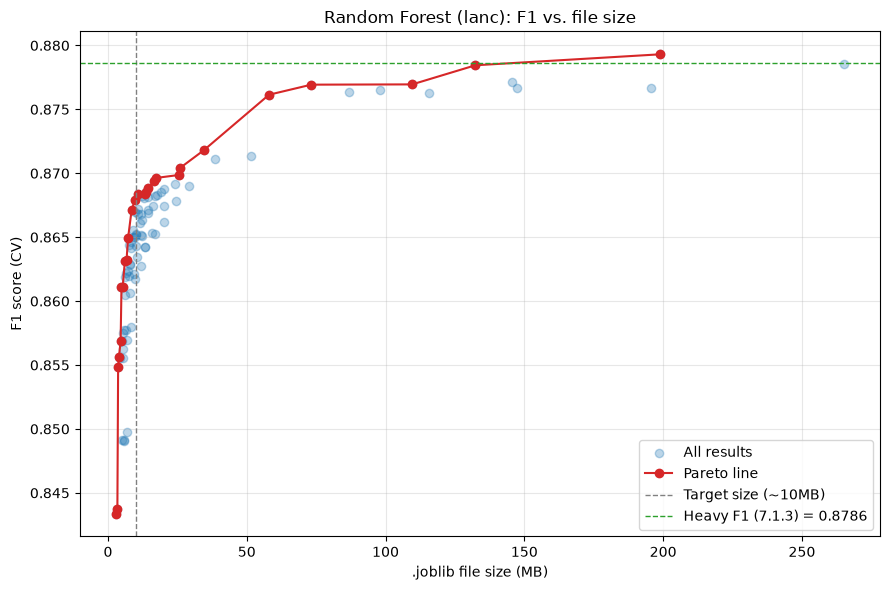

In [7]:
plt.figure(figsize=(9, 6))
plt.scatter(all_results_df["size_mb"], all_results_df["f1"], alpha=0.3, label="All results")
plt.plot(pareto_df["size_mb"], pareto_df["f1"], marker="o", color="tab:red", label="Pareto line")

plt.axvline(10, color="gray", linestyle="--", linewidth=1, label="Target size (~10MB)")
plt.axhline(0.8786, color="tab:green", linestyle="--", linewidth=1, label="Heavy F1 (7.1.3) = 0.8786")

plt.xlabel(".joblib file size (MB)")
plt.ylabel("F1 score (CV)")
plt.title("Random Forest (lanc): F1 vs. file size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Observation: The Best Point on the Pareto Front and the Heavy Model

It is worth noting that the best (largest) point on the Pareto front from this search - `max_depth=500, min_samples_leaf=2, n_estimators=1500`, F1=0.8793, size=199.0MB - appears to outperform the heavy model from `7.1.3` (F1=0.8786, size=199MB). At first glance, this might seem as though we have found a better combination than the one selected by `GridSearchCV` in `7.1.3`.

This is not the case - this is **exactly the same hyperparameter combination** that `GridSearchCV` selected as the best in `7.1.3` (`max_depth=500, max_features='log2', min_samples_leaf=2, n_estimators=1500`).

We did not find a different, better model - we simply measured the same model in a different way:
- F1=0.8793 here is an estimate obtained through 5-fold cross-validation on the TRAIN set (`cross_val_score`)
- F1=0.8786 in `7.1.3` is the result on the TEST set, measured exactly once, after `GridSearchCV` (which internally also uses 5-fold CV on the TRAIN set) selected this combination as the best

The difference of 0.0007 is expected variance between the CV estimate and the actual result on the separate test set - it does not indicate that one estimate is "more accurate" or that the model is better here, only that they are two different, slightly imperfect measurements of the same thing.

This nicely demonstrates why the test set is consistently kept untouched throughout this work - and why the CV F1 from our light search (which we see in the tables) should be interpreted as an estimate, not as a guaranteed result, until it is confirmed on the TEST set through `train_and_evaluate()`.


## Izbor finalne kombinacije

Biramo `max_depth=40, min_samples_leaf=5, n_estimators=1000, max_features='log2'`:

- Veličina (9.7MB) je blizu ciljne vrednosti od ~10MB, sa malo prostora ispod granice

- Leži na Pareto frontu, i predstavlja bolji odnos F1/veličina od suseda na frontu:
    - Prethodna tačka (`max_depth=35, min_samples_leaf=5, n_estimators=1000`) je manja (8.5MB) ali daje 0.0008 manji F1 - korak na 40/5/1000 nosi bolji odnos F1/veličina (+0.0008 F1 za samo +14% veličine) nego što bi taj korak unazad uštedeo, pa se isplati napraviti
    - Sledeća tačka (`max_depth=40, min_samples_leaf=4, n_estimators=1000`) daje samo +0.0004 F1 za dodatnih 13% veći fajl (11.0MB) - slab odnos, ne isplati se

- Grafik F1 vs. file size pokazuje da prava, znatno bolja tačka postoji tek na ~58MB (`max_depth=200, min_samples_leaf=3, n_estimators=1000`, F1 0.8761) - ali to bi ~6x premašilo ciljnu veličinu, pa ostajemo pri manjem, ciljanom modelu

- Identična kombinacija kao kod `lem` varijante (`7.2.2`), čak i identična veličina fajla (9.7MB) - potvrđuje raniju opservaciju da lemmatizovana i lancaster-stemovana varijanta (obe agresivnije/drugačije grupišu reči od Porter stemminga) dosledno daju optimum na `max_depth=40`, dok `stem` i `base` daju optimum na `max_depth=35`

- Za razliku od `stem` i `base` varijante, gde je optimalna kombinacija bila `max_depth=35`, ovde je `max_depth=40` blago bolji izbor - pokazuje da pretpostavka o identičnoj optimalnoj kombinaciji kroz sve varijante ne važi u potpunosti, iako je razlika mala

- U odnosu na heavy verziju (`7.1.3`: F1-0.8786, size-199MB), očekujemo gubitak od ~0.011 F1 (oko 1.2%) za fajl koji je ~21x manji

Napomena:
- F1 iznad je procena kroz cross-validation na TRAIN skupu
- Finalna evaluacija na TEST skupu, koji do sad nismo koristili, dobija se tek sada, kroz `train_and_evaluate()` iz `src/modeling.py`

========== lite_random_forest (lanc) ==========
Best parameters: {'max_depth': 40, 'max_features': 'log2', 'min_samples_leaf': 5, 'n_estimators': 1000}
GridSearchCV time: 142.5s

Accuracy  : 0.8593
Precision : 0.8235
Recall    : 0.9160
F1        : 0.8673


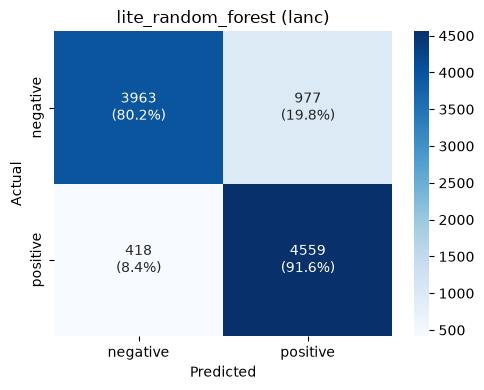


Saved:
  ..\models\lite_random_forest_lanc.joblib
  ..\results\metrics\lite_random_forest_lanc.json
  ..\results\figures\lite_random_forest_lanc_confusion_matrix.png


In [8]:
model = RandomForestClassifier(random_state=1)

param_grid = {
    "n_estimators": [1000],
    "max_depth": [40],
    "max_features": ["log2"],
    "min_samples_leaf": [5],
}

metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="lite_random_forest",
    variant="lanc",
)

## Feature Importance - Comparison with the Heavy Version

`feature_importances_` represents a measure of feature importance.

The value indicates how much a particular term contributed to the reduction of "impurity" across all splits.

A higher value means that the feature made a greater contribution to reducing impurity in the splits of the Random Forest model's trees.

The same principle as in `7.1.0` - `feature_importances_` averaged across all trees.

We expect the lite version, with significantly fewer trees (1000 vs 1500) and shallower trees (`max_depth=40` vs 500), to use a smaller portion of the vocabulary than the heavy version (which used 100% of the terms) - there is less opportunity for "rare", specific terms to receive non-zero importance.


In [10]:
best_model = joblib.load("../models/lite_random_forest_lanc.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_lanc.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
importances = best_model.feature_importances_

top_idx = np.argsort(importances)[-20:][::-1]

print("Top 20 most influential terms (lite):")
for idx in top_idx:
    print(f"  {feature_names[idx]:30s}  {importances[idx]:.4f}")

n_zero_importance = np.sum(importances == 0)
print(f"\nNumber of terms that the forest never used for splitting: {n_zero_importance} out of {len(importances)} ({n_zero_importance / len(importances):.1%})")

Top 20 most influential terms (lite):
  gre                             0.0066
  poor                            0.0062
  worst                           0.0050
  wast                            0.0050
  bor                             0.0047
  beauty                          0.0042
  bad                             0.0042
  worst movy                      0.0039
  not ev                          0.0039
  bad act                         0.0035
  best                            0.0034
  minut                           0.0034
  could                           0.0034
  amaz                            0.0034
  aw                              0.0033
  on best                         0.0032
  bril                            0.0030
  lov                             0.0030
  favorit                         0.0029
  horr                            0.0028

Number of terms that the forest never used for splitting: 49129 out of 68378 (71.8%)


## Conclusions

- Instead of the standard `GridSearchCV` (which selects hyperparameters exclusively based on F1 score), the light version was searched using a targeted approach that measured both F1 and the actual `.joblib` file size for each combination - coarse search followed by fine search, and then Pareto analysis

- The F1 vs. file size plot revealed that the curve is not smooth: after ~13MB there is a region where additional size does not contribute much to F1, while a real jump occurs only at ~58MB (F1 0.8761).
Since the goal was to stay close to ~10MB, this jump was not used, but it is worth mentioning as a finding that would be interesting if the size limit had not been a priority

- Selected final combination: `max_depth=40, min_samples_leaf=5, n_estimators=1000, max_features='log2'` - identical to the combination used for the `lem` variant (`7.2.2`), unlike `stem`/`base`, where the optimum was `max_depth=35`. This confirms the earlier observation: the lemmatized and Lancaster-stemmed variants consistently reach their optimum at `max_depth=40`, while the less aggressively reduced variants (`stem`, `base`) reach their optimum at `max_depth=35`

- Final results on the TEST set (`lite_random_forest`, lanc):
  - Accuracy  : 0.8593
  - Precision : 0.8235
  - Recall    : 0.9160
  - F1        : 0.8673
  - Saved file size: 9.6 MB

- Test F1 (0.8673) is very close to the CV estimate from the search (0.8679, difference 0.0006) - similarly to `stem` and `base`, the cross-validation estimate was not optimistically biased

- Compared to the heavy version (`7.1.3`: F1=0.8786, size=199MB), the light version loses 0.0113 F1 (~1.29%), with a file that is ~21x smaller - in the same range as `lem` (~1.53% for ~21x) and `base` (~1.83% for ~25x)

- Recall (0.9160) is significantly higher than precision (0.8235) - the model successfully identifies most positive reviews (91.6% correctly identified), with somewhat more false positives (the negative class is correctly identified in 80.2% of cases). The same asymmetry exists in the heavy version (recall 0.9052 > precision 0.8535), only slightly more pronounced here - a consistent pattern across all four light variants

- Feature importance: the light version used only 28.2% of the vocabulary for splits (49,129 out of 68,378 terms were never used), compared to 94.4% for the heavy version (5.6% unused) - a direct consequence of the smaller depth (40 vs. 500) and fewer trees (1000 vs. 1500)

- The core of the most influential terms largely overlaps with the heavy version (bad, worst, wast, poor, gre, aw, "not ev", bor, best, "worst movy", lov, horr - appearing in the top 20 for both models), confirming that the light model, although much smaller, relies on the same robust sentiment signals. Several terms appear only in the heavy version (no, terr, "wast tim", excel, perfect, not, noth, stupid), while the light version introduces its own semantically meaningful terms (beauty, "bad act", minut, could, amaz, "on best", bril, favorit)

- Here too, traces of aggressive Lancaster stemming are visible (gre, bor, terr, horr, bril, "not ev", "worst movy") - the same characteristic observed in the heavy version in `7.1.3`

<br>

Overall conclusion: the cost of ~1.29% F1 for a ~21x smaller file represents a favorable trade-off, almost identical in nature to the results for `lem` (~1.53% for ~21x). With all four Random Forest light variants now completed, the pattern is clearly established: the F1 loss ranges within a narrow ~1.3-1.8% range, while the model size reduction factor varies dramatically (~21-25x for `base`/`lem`/`lanc`, ~700x for `stem`) - a direct consequence of how much the heavy `GridSearchCV` happened to inflate the original model for that particular variant, rather than fundamental differences in the problem itself.
